## The Point of K-Means

Exploratory analysis asks "what's in this data?" before you test anything

K-Means helps with one version of that: are there natural groups of students, and if so what are they like?

We typically use a subset of columns to answer certain questions:

- We want to know if there are different groups of students based on SES backgrounds.   
  We let K-Mean find clusters of students based on  `[income, parent's educations, parent's occupation]`, 

- We want to ask if there are different groups of students based on the amount of effort they put in.
  We let K-Mean find clusters of students based on  `[study hours, attendence pct]`

- If we give K-Means everything at once, it answers a muddled question: "Which students are similar on everything at once?" \
  Groups would be split by whatever column happened to dominate, and becomes hard to explain.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

In [2]:
# Data Preprocessing 

# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)


Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## Missing rows

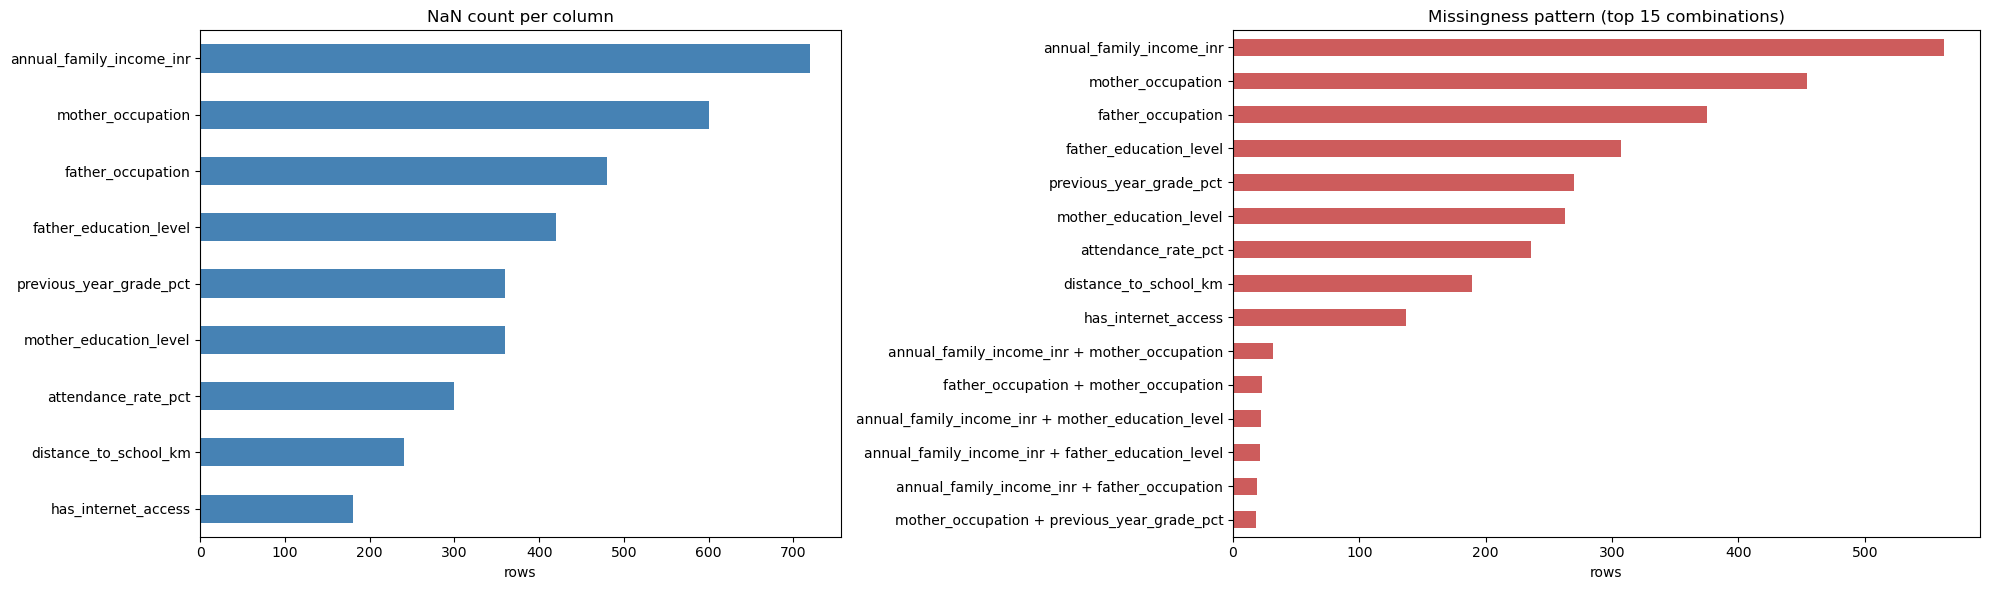

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [3]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

## Imputing Missing values
Parent education / occupation NULLs look random, so they become their own "Unknown" category. This learns nothing from the data, so its safe to do before CV.

In [4]:
parent_cols = ['father_education_level', 'mother_education_level', 'father_occupation', 'mother_occupation']

df[parent_cols] = df[parent_cols].fillna("Unknown")

nulls = df.isna().sum()

nulls[nulls > 0]

annual_family_income_inr    720
has_internet_access         180
distance_to_school_km       240
attendance_rate_pct         300
previous_year_grade_pct     360
dtype: int64

## Filling the rest

Fills values have to come from training rows only.
The `GroupImputer` does a fit and transform inside each CV fold.

| Column | Fill with | Why |
|---|---|---|
| `annual_family_income_inr` | median per `family_income_bracket`| bracket is complete and tracks income closely (Low (103k) vs High (3M)); the overall median (~350k) would put a high-income family in the middle |
| `distance_to_school_km` | median per `residence_type` | Rural (5.4 km) vs Urban (1.7 km) |
| `has_internet_access` | most common value per `residence_type`| Rural (36%) vs Urban (60%); the overall mode would give everyone 0 |
| `attendance_rate_pct`, `previous_year_grade_pct` | overall median | nothing else predicts them well (correlation <= 0.29); |

Rows with these missing values have about the same final grade as complete rows, so the gaps look random and simple filling is reasonable. `family_income_bracket` is dropped once income is filled.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # income -> median of income bracket
        self.income_medians_ = X.groupby("family_income_bracket")["annual_family_income_inr"].median()

        # distance -> median of residence type
        self.distance_medians_ = X.groupby("residence_type")["distance_to_school_km"].median()

        # internet -> most common value for residence type
        internet = X.groupby("residence_type")["has_internet_access"]
        self.internet_modes_ = internet.agg(lambda s : s.mode()[0])

        # attendance and previous grade -> overall median
        self.other_medians_ = X[['attendance_rate_pct', 'previous_year_grade_pct']].median()

        self.columns_ = list(X.columns)

        return self

    def transform(self, X):
        X = X.copy()

        income_fill = X["family_income_bracket"].map(self.income_medians_)
        X["annual_family_income_inr"] = X["annual_family_income_inr"].fillna(income_fill)

        distance_fill = X["residence_type"].map(self.distance_medians_)
        X["distance_to_school_km"] = X["distance_to_school_km"].fillna(distance_fill)

        internet_fills = X["residence_type"].map(self.internet_modes_)
        X["has_internet_access"] = X["has_internet_access"].fillna(internet_fills)

        X = X.fillna(self.other_medians_)

        return X

    def get_feature_names_out(self, input_features=None):
        return self.columns_

## Skewed income column: annual_family_income_inr

From the histogram above, we can see that the annual_family_income_inr column is very right-skewed. In the data it ranges from about ₹60,000 to ₹19.6 million, a factor of more than 300. Most families sit near the low end and a few earn far more. On the raw scale, the few very rich families stretch the axis. This creates the problems of the ultra-wealthy outliers having too much influence in linear models. 

In such cases, a log transformation is ideal because algorithms like linear regression, logistics regression, K-means clustering and PCA are highly sensitive to extreme values and perform better when features are normally distributed. As the log is a monotonically increasing function, it naturally squashes massive numbers closer together while preserving the exact rank order of data.

In [6]:
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
print(f"log_income skew: {np.log(df['annual_family_income_inr']).skew()}")

annual_family_income_inr skew: 4.53032946580657
log_income skew: 0.4205426254784524


In [7]:
from sklearn.preprocessing import FunctionTransformer

def log_transform():
    return FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )

## Schema Setup

Based off the variable histograms above, we can deduce which of the columns are discrete/continuous/categorical and we can form the column schema below. 

In [8]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'grade_class'

CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'annual_family_income_inr'
]

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Text labels
CATEGORICAL_COLS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'father_occupation',
    'mother_occupation', 
    'scholarship_status'
]

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [9]:
X = df[PREDICTOR_COLS]
print('X:', X.shape)

X: (12000, 24)


## Highly Correlated Predictors 



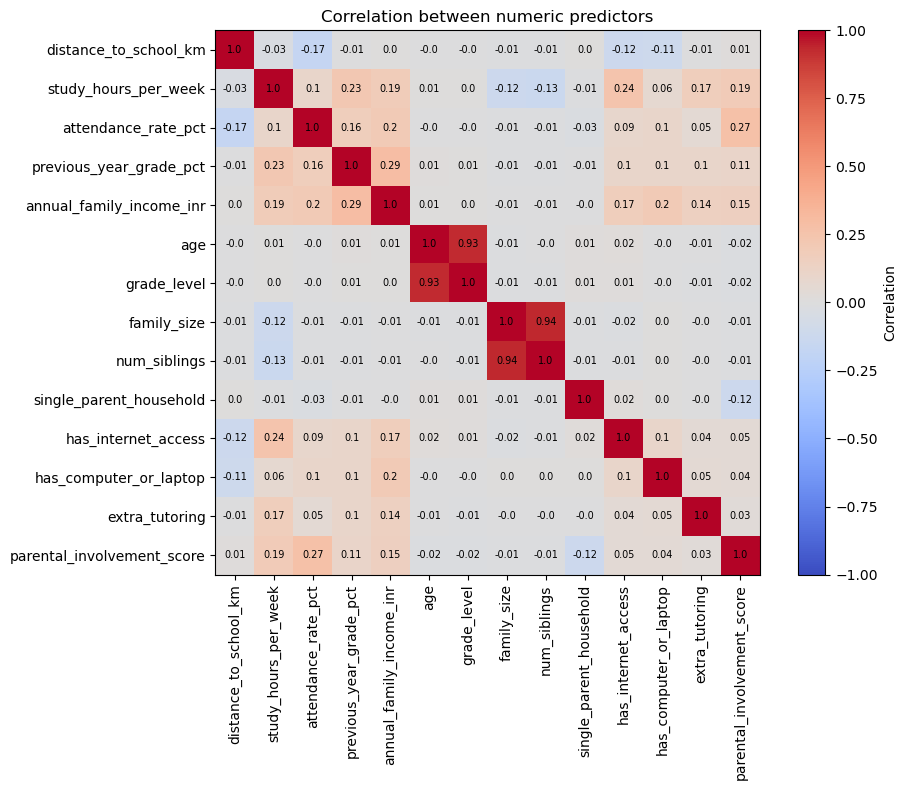

In [10]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Both columns in each pair are almost uncorrelated with `final_grade_pct` (|r| about 0.00 for age/grade level and 0.05 for family size/siblings), so the choice is made on what the variable means rather than on the target. This also avoids using the target before the train/test split.

In [11]:
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Numeric final grade
Y_classification = df[CLASSIFICATION_TARGET]  # Grade band
print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (12000, 22)


## Exploratory Data Analysis: K-Means Clustering (Socioeconomic features)

Cluster students on socioeconomic features only, then check whether the groups differ in effort and grades.

### Step 1: Select features

In [34]:

km_df = GroupImputer().fit_transform(df)
km_df = km_df.drop(columns="family_income_bracket")

# ======= Ordinal encoding education ====== #
edu_rank = {
    "No Formal Education": 0,
    "Primary": 1,
    "Secondary": 2,
    "Higher Secondary": 3,
    "Bachelor's Degree": 4,
    "Master's Degree": 5,
    "Doctorate": 6
}

km_df['father_edu'] = km_df['father_education_level'].map(edu_rank)
km_df['mother_edu'] = km_df['mother_education_level'].map(edu_rank)

# 'Unknown' doesn't map to a number, fill with median
km_df['father_edu'] = km_df["father_edu"].fillna(km_df['father_edu'].median())
km_df['mother_edu'] = km_df["mother_edu"].fillna(km_df['mother_edu'].median())

# ======= Log income ====== #
km_df['log_income'] = np.log(km_df['annual_family_income_inr'])

# ======= Do household columns track SES? ===== #
household = ['single_parent_household', 'family_size', 'num_siblings']

print("Correlation of household columns with SES features:")
display(km_df[household + ['log_income', 'father_edu', 'mother_edu']].corr().loc[household, ['log_income', 'father_edu', 'mother_edu']].round(3))

# ======= SES columns ====== #
ses_cols = ['log_income', 'father_edu', 'mother_edu']

print("Description of SES columns we are going to cluster on:")
display(km_df[ses_cols].describe().round(2))

Correlation of household columns with SES features:


,log_income,father_edu,mother_edu
single_parent_household,-0.003,0.013,0.005
family_size,0.002,0.007,0.011
num_siblings,0.001,0.009,0.008


Description of SES columns we are going to cluster on:


,log_income,father_edu,mother_edu
count,12000.00,12000.00,12000.00
mean,12.83,2.69,2.71
std,0.99,1.50,1.51
min,11.00,0.00,0.00
25%,12.17,2.00,2.00
50%,12.77,3.00,3.00
75%,13.39,4.00,4.00
max,16.79,6.00,6.00


Why these features:
- SES is usually measured by income, education and occupation. We've included income and education directtly. 
- Parents' occupation was left out as it has no natural order, and being a 'Homemaker' (the most common for mothers) goes with the highest median income, so it can't be ranked sensibly
- `has_internet_access` and `has_computer_or_laptop` were left out of the clustering. They are 0/1 columns, and in a separate experiment we conducted, K-Means tended to split along those values since everyone with the same value sat at exactly the same point. They ended up driving the clusters. Leaving them out allows K-Means to find the SES boundary by itself.

- Other columns were checked and left out:
    - `family_income_bracket` is a banded version of income column

    - `scholarship_status` is a result of low SES, not a measure of it
    - `single_parent_household`, `family_size` and `num_siblings` have almost no correlation with income or education (r approx 0)
    - `distance_to_school_km` mostly reflects rural vs urban.
- `school_type`, `residence_type` and the grade columns are kept out on purpose, so they can be compared between clusters afterwards

### Step 2: Scale features and choose k

We use Inertia & Silhouette to determine which k to pick.

Inertia
- Measures how compact the clusters are
- Lower is better for compactness, but inertia generally increases as we add more clusters, even if the extra clusters aren't meaningful.
- To choose no. clusters, we plot inertia against K and look for an elbow point after which adding clusters brings diminishing returns

Silhouette
- The silhouette score tells use whether each point is closer to its own cluster or other clusters
- Near 1: Well within its cluster and separated from others
- Near 0: Near a boundary between cluters
- Below 0: Closer on average to another cluster than its own

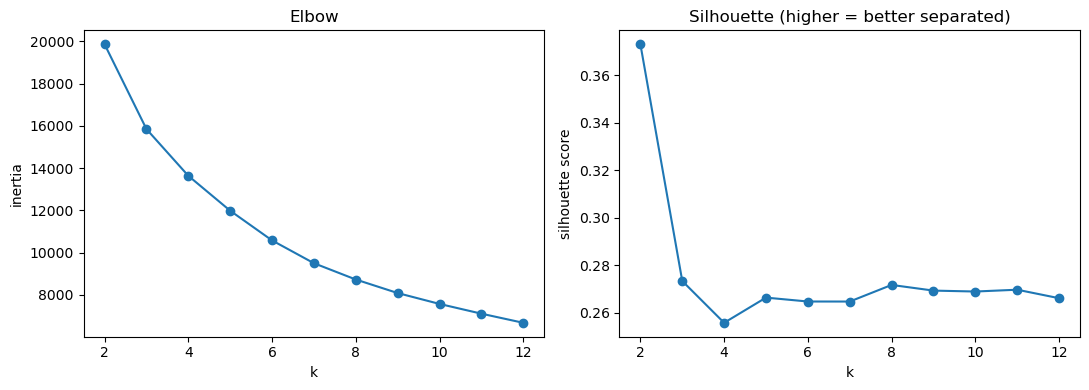

In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km_X = StandardScaler().fit_transform(km_df[ses_cols])

inertias = []
sil_scores = []

for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(km_X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(km_X, km.labels_, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(2, 13), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow")

axes[1].plot(range(2, 13), sil_scores, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette (higher = better separated)")

plt.tight_layout()
plt.show() 

We pick k = 2
- Silhouette has one clear peak at k = 2 (0.37). It then drops to 0.27 at k = 3 and stays flat at 0.26 to 0.27 for every k up to 12, so no other number of clusters stands out.

- The elbow plot doesn't help: inertia drops smoothly with no clear bend, so the choice rests on the silhouette.

- With only 3 continuous features, there are no 0/1 columns to inflate the silhouette score, so the higher value really does mean better-separated groups.

- k = 2 is also the simplest result to interpret: a lower-SES and a higher-SES group.

### Step 3: Fit k = 2 and profile the clusters

Clusters are numbered so 0 = lower SES and 1 = higher SES.

Cluster counts breakdown:


cluster
0    6893
1    5107
Name: count, dtype: int64

Cluster means breakdown:


,log_income,father_edu,mother_edu
cluster,,,
0,12.28,1.81,1.83
1,13.57,3.88,3.91


Cluster income breakdown:


cluster
0    228351.0
1    690145.0
Name: annual_family_income_inr, dtype: float64

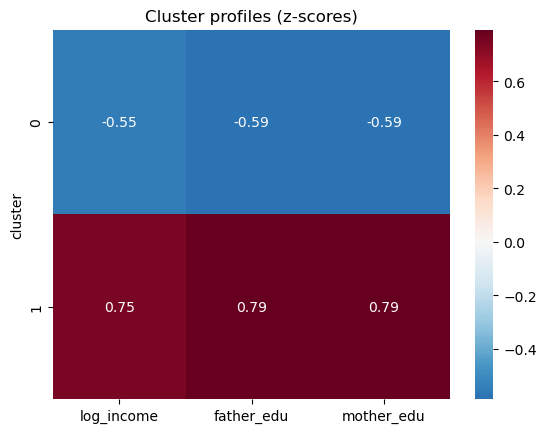

In [36]:
km = KMeans(n_clusters=2, n_init=10, random_state=42)
km_df["cluster"] = km.fit_predict(km_X)

# Renumber so 0 = lower income and 1 = higher
income_rank = km_df.groupby("cluster")["log_income"].mean().rank().astype(int) - 1
km_df["cluster"] = km_df["cluster"].map(income_rank)

print("Cluster counts breakdown:")
display(km_df["cluster"].value_counts().sort_index())

print("Cluster means breakdown:")
display(km_df.groupby('cluster')[ses_cols].mean().round(2))

print("Cluster income breakdown:")
display(km_df.groupby('cluster')['annual_family_income_inr'].median())

import seaborn as sns

# average z-score per cluster, 0 = overall average
km_X_df = pd.DataFrame(km_X, columns=ses_cols)
km_X_df["cluster"] = km_df["cluster"].values
profile = km_X_df.groupby("cluster").mean()

sns.heatmap(profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-scores)")
plt.show()

### Step 4: Compare clusters on grades, digital access and background

### Grades

Average grades and effort by cluster


,final_grade_pct,grade_change,study_hours_per_week,attendance_rate_pct,extra_tutoring,parental_involvement_score
cluster,,,,,,
0,63.67,4.59,13.79,84.83,0.19,3.15
1,71.36,4.64,15.28,87.22,0.29,3.37


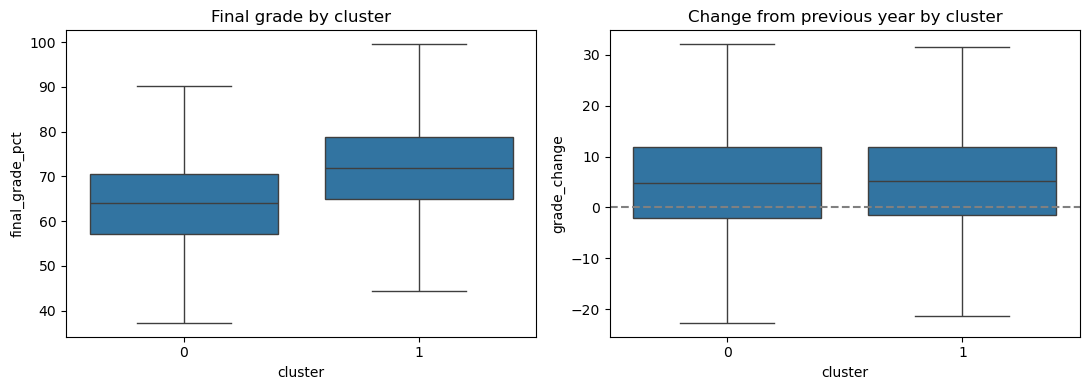

In [ ]:
km_df["grade_change"] = km_df["final_grade_pct"] - km_df["previous_year_grade_pct"]

print("Average grades and effort by cluster:")
display(
    km_df.groupby("cluster")[
        [
            "final_grade_pct",
            "grade_change",
            "study_hours_per_week",
            "attendance_rate_pct",
            "extra_tutoring",
            "parental_involvement_score",
        ]
    ]
    .mean()
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=km_df,
    x="cluster",
    y="final_grade_pct",
    showfliers=False,
    ax=axes[0],
)
axes[0].set_title("Final grade by cluster")

sns.boxplot(
    data=km_df,
    x="cluster",
    y="grade_change",
    showfliers=False,
    ax=axes[1],
)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("Change from previous year by cluster")

plt.tight_layout()
plt.show()

### Digital Access

Internet and computer access weren't used for clustering, so we check how access differs between the SES groups and how it relates to grades within each group

In [30]:
# 0 = neither, 1 = internet or computer, 2 = both
km_df["devices"] = (
    km_df["has_internet_access"].astype(int)
    + km_df["has_computer_or_laptop"]
)

print("Share of each cluster with internet / a computer")
display(
    km_df.groupby("cluster")[
        ["has_internet_access", "has_computer_or_laptop"]
    ].mean().round(2)
)

print("Average final grade by cluster and number of devices")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["devices"],
        values=km_df["final_grade_pct"],
        aggfunc="mean",
    ).round(1)
)

print("Number of students by cluster and number of devices")
display(pd.crosstab(km_df["cluster"], km_df["devices"]))

Share of each cluster with internet / a computer


,has_internet_access,has_computer_or_laptop
cluster,,
0,0.44,0.34
1,0.58,0.51


Average final grade by cluster and number of devices


devices,0,1,2
cluster,,,
0,61.8,64.4,66.0
1,68.5,71.1,73.8


Number of students by cluster and number of devices


devices,0,1,2
cluster,,,
0,2654,3085,1154
1,1155,2328,1624


### Background

In [31]:
# Rows add up to 1
print("School type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["school_type"],
        normalize="index",
    ).round(2)
)

print("Residence type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["residence_type"],
        normalize="index",
    ).round(2)
)

print("Scholarship status (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["scholarship_status"],
        normalize="index",
    ).round(2)
)

School type (share of each cluster)


school_type,Government,Government-Aided,Private-Unaided
cluster,,,
0,0.45,0.2,0.36
1,0.45,0.2,0.35


Residence type (share of each cluster)


residence_type,Rural,Semi-Urban,Urban
cluster,,,
0,0.35,0.23,0.42
1,0.36,0.22,0.42


Scholarship status (share of each cluster)


scholarship_status,Full,No Scholarship,Partial
cluster,,,
0,0.10,0.70,0.20
1,0.04,0.89,0.07


### Findings so far

**Cluster structure**

- There is one natural split in income and parents’ education: **lower SES** (cluster 0, 57% of students, median income 230k, parents’ education around primary to secondary level) and **higher SES** (cluster 1, 43%, median income 690k, parents’ education around higher secondary to a bachelor’s degree).

- This is the clearest structure found (silhouette 0.37). It is still moderate, so the groups are more of a continuum rather than completely separate types.

**Grades**

- Higher-SES students average about 8 points higher (71.4 vs. 63.7), and their whole grade range is shifted up.

- Both groups improved on the previous year by about the same amount (+4.6), so the higher-SES group starts ahead rather than pulling further ahead.

- Effort differs only a little: 13.8 vs. 15.3 study hours per week, and 85% vs. 87% attendance. Tutoring is the clearest difference: 29% vs. 19%.

**Digital access**

- Higher-SES students are more likely to have devices: 58% have internet and 51% have a computer, compared with 44% and 34% in the lower-SES group.

- Within both groups, each extra device goes with about 2 to 3 more points:
  - Lower SES: 61.8 (neither) → 64.4 (one) → 66.0 (both)

  - Higher SES: 68.5 → 71.1 → 73.8
- At every level of access, higher-SES students are about 7 to 8 points ahead.
- SES and digital access look roughly **additive**: background is the bigger factor, and devices go with a similar extra gain in both groups.
- A lower-SES student with both devices (66.0) still averages below a higher-SES student with neither (68.5).

**Background**

- School type and residence are almost identical in both groups (about 45% government schools and about 35% rural), so neither separates the SES groups in this data.

- Scholarships go mostly to lower-SES students: 30% have one (full or partial), compared with 11% of the higher-SES group.

### Step 5: Visualize Clusters in 2D (PCA)

PCA reduces the 3 scaled features into 2 components so the clusters can be plotted. With only 2 clusters, a single scatter plot colored by cluster is readable

Share of variance explained by each component


PC1    0.668
PC2    0.171
dtype: float64

What each component is made of


,PC1,PC2
log_income,0.57,0.82
father_edu,0.58,-0.46
mother_edu,0.58,-0.34


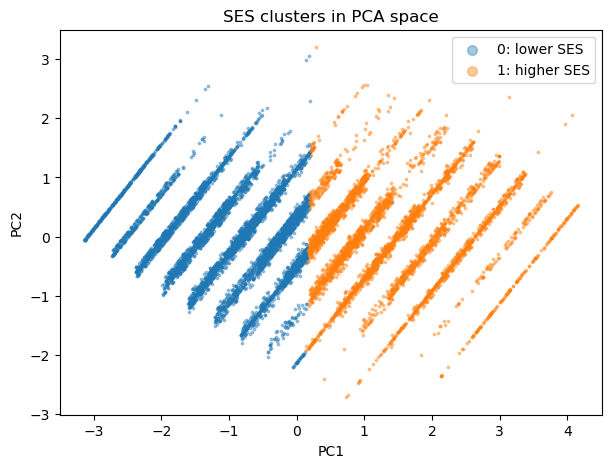

In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(km_X)

print("Share of variance explained by each component")
display(
    pd.Series(
        pca.explained_variance_ratio_,
        index=["PC1", "PC2"],
    ).round(3)
)

print("What each component is made of")
display(
    pd.DataFrame(
        pca.components_.T,
        index=ses_cols,
        columns=["PC1", "PC2"],
    ).round(2)
)

lower = km_df["cluster"].values == 0

plt.figure(figsize=(7, 5))
plt.scatter(
    pcs[lower, 0], pcs[lower, 1],
    s=3, alpha=0.4, label="0: lower SES",
)
plt.scatter(
    pcs[~lower, 0], pcs[~lower, 1],
    s=3, alpha=0.4, label="1: higher SES",
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=4)
plt.title("SES clusters in PCA space")
plt.show()

Findings for PCA
- Two components explain 84% of the variance. PC1 (67%) is overall SES: income and both parents’ education load about equally. PC2 (17%) mostly separates income from education, for example, families with high income but less-educated parents.

- The two clusters split cleanly along PC1: lower SES on the left, higher SES on the right. They meet in the middle without a gap, which fits the moderate silhouette: the split is a boundary drawn through a continuum.

- The points fall in diagonal stripes because parents’ education is a whole number from 0 to 6. Each stripe is one combination of father’s and mother’s education, and income spreads students along it.

Step 6: Check cluster stability
Would a different sample of students give the same split? If not, the boundary is partly luck.
- Shuffle the students and split them into two halves of 6,000.
- Fit one model on each half, then have both models label all 12,000 students so their results can be compared.
- Score the agreement with the adjusted Rand index (ARI): 1 = identical groupings, 0 = no better than random. Cluster numbers don’t matter, only which students end up together.
- Repeat 10 times.

In [38]:
from sklearn.metrics import adjusted_rand_score

# Fit on two random halves, then compare how each half's model labels everyone
half_scores = []

for seed in range(10):
    idx = np.random.default_rng(seed).permutation(len(km_X))
    half_a = km_X[idx[:6000]]
    half_b = km_X[idx[6000:]]

    km_a = KMeans(n_clusters=2, n_init=10, random_state=seed).fit(half_a)
    km_b = KMeans(n_clusters=2, n_init=10, random_state=seed + 100).fit(half_b)

    half_scores.append(
        adjusted_rand_score(km_a.predict(half_b), km_b.predict(half_b))
    )

print(np.round(half_scores, 3))
print("mean:", round(np.mean(half_scores), 3))

[0.962 0.999 0.989 0.956 0.905 0.972 0.993 0.989 0.987 0.942]
mean: 0.969


Findings: Step 6 (stability)
- The two halves found nearly the same split every time (ARI 0.91 to 1.0, mean 0.97), so the lower/higher SES boundary doesn’t depend on which students are in the sample.
- Stability doesn’t mean the groups are natural types. K-Means can cut a continuum in the same place every time, and the PCA plot shows no gap between the clusters. The split is a reliable boundary, not proof of two separate kinds of student.

## Prep

In [20]:
# Setup helper functions for data preparation so that X-train and X-test can be massaged into a format palatable to each model 

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, RegressorMixin
from pygam import LinearGAM, s, l      # pip install pygam
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from scipy.stats import norm

# Columns with no natural order: one-hot encoded
ONEHOT_COLUMNS = ['gender', 'school_type', 'residence_type', 'academic_year',
                  'father_occupation', 'mother_occupation', 'father_education_level', 'mother_education_level']

# Columns with a clear order (lowest level first): ordinal encoded
ORDINAL_COLUMNS = {
    # 'father_education_level': [
    #     'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
    #     "Bachelor's Degree", "Master's Degree", 'Doctorate',
    # ],
    # 'mother_education_level': [
    #     'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
    #     "Bachelor's Degree", "Master's Degree", 'Doctorate',
    # ],
    'family_income_bracket': ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'scholarship_status': ['No Scholarship', 'Partial', 'Full'],
}

def build_prep(scale):
    # Logging for family income
    log_step = ColumnTransformer(
        [("log", log_transform(), ["annual_family_income_inr"])],
        verbose_feature_names_out=False,
        remainder="passthrough"
    ).set_output(transform="pandas")

    # one-hot and ordinal encoders are the same for every family. Only scaling differs
    scale_encode_step = ColumnTransformer([
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
        ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
        ('num', StandardScaler() if scale else 'passthrough', NUMERIC_COLS),
    ])

    return Pipeline([
        ("impute", GroupImputer()),
        ("log", log_step),
        ("scale", scale_encode_step)
    ])

def make_linear_prep():  # OLS, Ridge, Lasso
    return build_prep(scale=True)

def make_gam_prep():     # GAM: splines handle the shape, so no scaling
    return build_prep(scale=False)

class GAMRegressor(BaseEstimator, RegressorMixin):
    # Wrapper so pygam's LinearGAM works inside a Pipeline and GridSearchCV
    # Smooth spline term for each continuous column, linear term for every other column
    def __init__(self, n_splines=10, lam=0.6):
        self.n_splines = n_splines
        self.lam = lam      # smoothing penalty, bigger = smoother curves

    def fit(self, X, y):
        first_continuous = X.shape[1] - len(NUMERIC_COLS)   # one-hot and ordinal columns come first
        last_continuous = first_continuous + len(CONTINUOUS_COLS)
        terms = l(0)
        for j in range(1, X.shape[1]):
            if first_continuous <= j < last_continuous:
                terms = terms + s(j, n_splines=self.n_splines, lam=self.lam)
            else:
                terms = terms + l(j)
        self.gam_ = LinearGAM(terms).fit(X, y)
        return self

    def predict(self, X):
        return self.gam_.predict(X)

def make_knn_prep():     # KNN: distances need scaled columns
    return build_prep(scale=True)

def make_tree_prep():    # decision tree, random forest
    return build_prep(scale=False)

def make_gbt_prep():     # gradient boosting
    return build_prep(scale=False)

def make_svr_prep():     # SVM: RBF kernel uses distances, so scale
    return build_prep(scale=True)

def compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test):
    # Returns (RMSE, MAE, R2, CV RMSE, mean Gaussian log-likelihood) of a fitted model on the test set
    test_predictions = fitted_model.predict(X_test)
    # CV RMSE on the training data: from the grid search if tuned, otherwise 5-fold cross_val_score
    if hasattr(fitted_model, 'best_score_'):
        cv_rmse = -fitted_model.best_score_
    else:
        cv_rmse = -cross_val_score(fitted_model, X_train, Y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
    # Likelihood uses the CV RMSE as the noise sd, so the test set is not used to choose it
    return (root_mean_squared_error(Y_test, test_predictions),
            mean_absolute_error(Y_test, test_predictions),
            r2_score(Y_test, test_predictions),
            cv_rmse,
            norm.logpdf(Y_test, loc=test_predictions, scale=cv_rmse).mean())



# Hyperparameter Tuning: Coarse-to-Fine Search
The main experiment below repeats a full grid search 20 times, so searching a large grid each time would be computationally expensive. To reduce this cost, a coarse-to-fine search is used: a one-off search over a wide, roughly log-spaced grid of values for each model, evaluated with 5-fold cross-validation on the training data only. The best value and its neighbours form a narrower grid, which the main experiment uses for its tuning.

# Unsupervised Learning: K-means and PCA (AI Slop)

Feature Exploration 
Dimensionality Reduction (PCA) / Clustering (K-means)

The setup below uses the shared predictors only. Numeric variables are standardized, ordinal variables keep their existing order, and all one-hot levels are retained so categories have equal pairwise distances. The encoded categorical variables are not standardized, so their weights differ from those of the numeric variables. This is exploratory preprocessing fitted on all available rows; predictive use would require fitting it on training data only.

PCA summarises variation in the prepared predictors. The first two components may not capture all of the structure in the data, and large loadings do not necessarily imply predictive importance.

K-means is fitted on all prepared predictors, not just the first two principal components. Silhouette scores use the same random sample of up to 2,000 students for each candidate. The highest score gives a provisional choice of cluster count; check the scores, sizes, stability and profiles before interpreting it. The seed comparison checks sensitivity to initialization, not sampling or preprocessing choices.

The PCA plots show the same two-dimensional projection coloured by cluster and by grade class. Clusters are fitted in the full predictor space, and grades are added only afterwards. Differences between groups are descriptive associations, not causal effects or independent validation; the clusters may change with the choice of preprocessing and distance weights.


In [21]:
# Setup for PCA and K-means
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

UNSUPERVISED_RANDOM_STATE = 0
CLUSTER_COUNTS            = range(2, 9)

# Keep all one-hot levels for distances; scale numeric columns only
unsupervised_prep = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
    ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
    ('numeric', StandardScaler(), NUMERIC_COLS),
])

unsupervised_values = unsupervised_prep.fit_transform(X)
X_unsupervised = pd.DataFrame(
    unsupervised_values,
    index=X.index,
    columns=unsupervised_prep.get_feature_names_out()
)

# Define PCA and candidate K-means models
pca_model = PCA()
kmeans_models = {
    count: KMeans(n_clusters=count, n_init=10, random_state=UNSUPERVISED_RANDOM_STATE)
    for count in CLUSTER_COUNTS
}

# Fit PCA and inspect explained variance and loadings
from IPython.display import display

pca_scores = pca_model.fit_transform(X_unsupervised)
explained_variance = pca_model.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components_for_80_percent = np.searchsorted(cumulative_variance, 0.80) + 1

print(f'Components needed for 80% of variance: {components_for_80_percent}')

pca_loadings = pd.DataFrame(
    pca_model.components_[:2].T,
    index=X_unsupervised.columns,
    columns=['PC1', 'PC2']
)
for component in pca_loadings.columns:
    largest_loadings = pca_loadings[component].abs().nlargest(5).index
    print(f'Largest {component} loadings:')
    display(pca_loadings.loc[largest_loadings, [component]].round(3))

# Compare cluster counts using inertia and silhouette score
from sklearn.metrics import adjusted_rand_score, silhouette_score

cluster_results = []
for count, model in kmeans_models.items():
    labels = model.fit_predict(X_unsupervised)
    cluster_results.append({
        'clusters':   count,
        'inertia':    model.inertia_,
        'silhouette': silhouette_score(
            X_unsupervised, labels, sample_size=min(2000, len(X_unsupervised)),
            random_state=UNSUPERVISED_RANDOM_STATE
        ),
    })

cluster_results = pd.DataFrame(cluster_results).set_index('clusters')
display(cluster_results.round(3))

selected_cluster_count = cluster_results['silhouette'].idxmax()
selected_kmeans = kmeans_models[selected_cluster_count]
cluster_labels = pd.Series(selected_kmeans.labels_ + 1, index=X.index, name='cluster')
print(f'Provisional cluster count: {selected_cluster_count}')

# Compare the selected solution with other random initializations
seed_stability = []
for seed in [1, 2, 3]:
    alternative_model = KMeans(n_clusters=selected_cluster_count, n_init=10, random_state=seed)
    alternative_labels = alternative_model.fit_predict(X_unsupervised)
    seed_stability.append({
        'random_state': seed,
        'adjusted_rand_score': adjusted_rand_score(selected_kmeans.labels_, alternative_labels)
    })
print('Agreement with the selected solution across random seeds:')
display(pd.DataFrame(seed_stability).set_index('random_state').round(3))

# Summarise predictors and grades after assigning clusters
profile_columns = [
    'study_hours_per_week', 'attendance_rate_pct',
    'previous_year_grade_pct', 'log_income'
]
cluster_data = X[profile_columns].copy()
cluster_data['cluster'] = cluster_labels
cluster_data['final_grade_pct'] = Y_regression
cluster_data['grade_class'] = Y_classification

cluster_profile = cluster_data.groupby('cluster')[profile_columns + ['final_grade_pct']].mean()
cluster_profile.insert(0, 'students', cluster_labels.value_counts().sort_index())
overall_profile = pd.DataFrame(
    [[len(cluster_data)] + cluster_data[profile_columns + ['final_grade_pct']].mean().tolist()],
    index=['Overall'], columns=cluster_profile.columns
)
print('Cluster means and overall means:')
display(pd.concat([cluster_profile, overall_profile]).round(2))

grade_distribution = pd.crosstab(cluster_labels, Y_classification, normalize='index')
print('Grade class distribution within each cluster:')
display((100 * grade_distribution).round(1))
print('School type distribution within each cluster (%):')
display((100 * pd.crosstab(cluster_labels, X['school_type'], normalize='index')).round(1))


ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

## Unsupervised Learning: Visualisation

In [ ]:
# PCA explained variance
component_numbers = np.arange(1, len(explained_variance) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, explained_variance)
axes[0].set(title='PCA explained variance', xlabel='Principal component', ylabel='Variance explained')
axes[1].plot(component_numbers, cumulative_variance, marker='o', markersize=3)
axes[1].axhline(0.80, color='grey', linestyle='--', label='80%')
axes[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='Cumulative variance')
axes[1].legend()
plt.tight_layout()
plt.show()

# Largest signed loadings for the first two principal components
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, component in zip(axes, ['PC1', 'PC2']):
    largest_features = pca_loadings[component].abs().nlargest(5).index
    loadings = pca_loadings.loc[largest_features, component].sort_values()
    ax.barh(loadings.index, loadings.values)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(title=f'{component}: largest loadings', xlabel='Loading')
plt.tight_layout()
plt.show()

# K-means diagnostics
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_results.index, cluster_results['inertia'], marker='o')
axes[0].set(title='K-means inertia', xlabel='Number of clusters', ylabel='Inertia')
axes[1].plot(cluster_results.index, cluster_results['silhouette'], marker='o')
axes[1].set(title='K-means silhouette score', xlabel='Number of clusters', ylabel='Silhouette score')
plt.tight_layout()
plt.show()

# Compare clusters and grade classes on the same PCA projection
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for cluster in sorted(cluster_labels.unique()):
    in_cluster = cluster_labels.to_numpy() == cluster
    axes[0].scatter(pca_scores[in_cluster, 0], pca_scores[in_cluster, 1],
                    s=10, alpha=0.35, label=f'Cluster {cluster}')

grade_classes = Y_classification.reindex(X_unsupervised.index)
for grade in grade_classes.value_counts().index:
    in_grade = grade_classes.to_numpy() == grade
    axes[1].scatter(pca_scores[in_grade, 0], pca_scores[in_grade, 1],
                    s=10, alpha=0.35, label=f'Grade {grade}')

for ax in axes:
    ax.set_xlabel(f'PC1 ({explained_variance[0]:.1%} variance)')
    ax.set_ylabel(f'PC2 ({explained_variance[1]:.1%} variance)')
    ax.legend()
axes[0].set_title('Coloured by cluster')
axes[1].set_title('Coloured by grade class')
plt.tight_layout()
plt.show()

# Grade class distribution within each cluster
grade_distribution.plot.bar(stacked=True, figsize=(8, 5), colormap='viridis')
plt.title('Grade class distribution by cluster')
plt.xlabel('Cluster')
plt.ylabel('Proportion of students')
plt.legend(title='Grade class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
